# Estado del arte: fugas suaves frente a las velocidades de corrida de 2023 y el análisis de sensibilidad de 2019 del BCE

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 06 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ubicar la tensión de liquidez del producto en el estado del arte que encontró la investigación: la prueba de tensión de liquidez de 2019 del BCE, los principios de Basilea, el informe sobre la turbulencia de 2023 y la teoría de las corridas bancarias;
- comparar la fuga suave de LiST con la corrida rápida sobre el mismo balance, en períodos de supervivencia y en la proporción de depósitos perdida al horizonte de cada corrida de 2023;
- comparar la salida a 30 días del LCR con la velocidad de las corridas de 2023;
- decir qué muestra y qué no muestra esta comparación sobre el producto.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`): las tres variantes de trayectoria `list-adverse.json`, `list-extreme.json` y `fast-run.json`, y `lcr-standard.json`, todos en `data/derived/C16/`. Las corridas observadas son la Tabla A.1 del informe del BCBS sobre la turbulencia de 2023, guardada por el motor como `TABLE_A1` dentro de los términos de extracto limitado del BIS.

La corrida rápida se calibra solo con las filas anteriores a 2023 y se evalúa con las filas de 2023 (cuaderno 04); cada proporción modelada de abajo es la salida acumulada de los segmentos del documento sobre la base de depósitos del modelo. Los montos están en miles de USD.

In [2]:
# Cargar los cuatro documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "lcr-standard"):
    documents[name] = json.loads((ROOT / "data" / "derived" / "C16" / f"{name}.json").read_text(encoding="utf-8"))
    print(name, "| calculado con riskvalidation", documents[name]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

variants = {name: documents[name] for name in ("list-adverse", "list-extreme", "fast-run")}

list-adverse | calculado con riskvalidation 0.8.1 | instalado 0.8.1
list-extreme | calculado con riskvalidation 0.8.1 | instalado 0.8.1
fast-run | calculado con riskvalidation 0.8.1 | instalado 0.8.1
lcr-standard | calculado con riskvalidation 0.8.1 | instalado 0.8.1


## Método

### Paso 1: el período de supervivencia de las tres variantes

La comparación necesita una medida que todas las variantes compartan: el período de supervivencia, el primer día en que la posición neta de liquidez se vuelve negativa, con "sobrevive el horizonte" cuando nunca lo hace (cuaderno 01). Las tres variantes difieren en la velocidad de la fuga: LiST Adverso y Extremo usan las tasas diarias suaves de las tablas del BCE, y la corrida rápida pone en el segmento corporativo no asegurado la tasa calibrada con las corridas anteriores a 2023, en un horizonte agudo de 5 días. La celda siguiente recalcula el período de supervivencia y la NLP mínima de cada variante a partir de su serie NLP versionada con el motor, y los pone junto a los valores versionados.

In [3]:
# El período de supervivencia y la NLP mínima de cada variante, desde la serie de NLP versionada, con el motor
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

print(f"{'variante':14s}{'horizonte':>10s}{'supervivencia':>30s}{'NLP mínima (mil millones USD)':>42s}{'día':>6s}")
survival_text = {}
for name, document in variants.items():
    nlp = np.array(document["outputs"]["path"]["ladder"]["nlp"])
    result = survival_period(nlp)
    low, low_day = minimum_nlp(nlp)
    committed = document["outputs"]["path"]["survival"]
    survival_text[name] = "sobrevive el horizonte" if result.survives else f"día {result.day}"
    same = result.day == committed["day"] and result.horizon == committed["horizon_days"]
    print(f"{name:14s}{result.horizon:10d}{survival_text[name]:>30s}{low / 1e6:42.2f}{low_day:6d}   igual que el documento: {'sí' if same else 'no'}")

variante       horizonte                 supervivencia             NLP mínima (mil millones USD)   día
list-adverse         125                        día 62                                    -40.97   125   igual que el documento: sí
list-extreme         125                        día 41                                    -65.65   125   igual que el documento: sí
fast-run               5        sobrevive el horizonte                                     13.80     1   igual que el documento: sí


### Paso 2: la proporción de depósitos perdida al horizonte de cada corrida

El período de supervivencia depende del CBC y de las salidas a la vez. Para comparar la velocidad de la fuga con lo ocurrido usamos solo la salida: para una corrida que perdió una proporción $F_i$ de sus depósitos en $n_i$ días (fila $i$ de la Tabla A.1) la contraparte del modelo es la salida acumulada de los segmentos en esos mismos $n_i$ días, como proporción de la base de depósitos $B$:

$$\hat F_i = \frac{1}{B} \sum_{s} \sum_{d \le n_i} O_s(d), \qquad \text{error}_i = F_i - \hat F_i$$

Una fila cuyo horizonte excede la escalera de una variante no puede evaluarse en ella (la corrida rápida tiene 5 días). La celda siguiente recalcula cada proporción modelada a partir de los segmentos versionados, compara con la evaluación versionada, e imprime las filas del horizonte más corto al más largo. Un error positivo significa que el modelo pierde menos de lo que perdió la corrida.

In [4]:
# La proporción modelada al horizonte de cada corrida de la Tabla A.1, para cada variante, contra la evaluación versionada
from riskvalidation.liquidity.runoff import TABLE_A1

modelled = {}
for name, document in variants.items():
    segments = document["outputs"]["path"]["ladder"]["segments"]
    base = document["outputs"]["scoring"]["model_deposit_base"]
    horizon = len(segments[0]["outflows"])
    modelled[name] = {run.row_id: None if run.days > horizon else sum(sum(s["outflows"][:run.days]) for s in segments) / base for run in TABLE_A1}

committed = {name: {e["row_id"]: e["modelled_share"] for e in document["outputs"]["scoring"]["table_a1_scoring"]} for name, document in variants.items()}
agree = all((modelled[n][r] is None) == (committed[n][r] is None) and (modelled[n][r] is None or abs(modelled[n][r] - committed[n][r]) < 1e-9) for n in modelled for r in modelled[n])

print(f"{'banco':16s}{'año':>6s}{'días':>6s}{'observada':>12s}{'Adverso':>10s}{'Extremo':>10s}{'corrida rápida':>16s}")
for run in sorted(TABLE_A1, key=lambda r: (r.days, r.year)):
    cells = ["-" if modelled[n][run.row_id] is None else f"{modelled[n][run.row_id]:.4f}" for n in modelled]
    print(f"{run.bank:16s}{run.year:6d}{run.days:6d}{run.outflow_share:12.2f}{cells[0]:>10s}{cells[1]:>10s}{cells[2]:>16s}")
print("mismas proporciones modeladas que la evaluación versionada:", "sí" if agree else "no")

banco              año  días   observada   Adverso   Extremo  corrida rápida
SVB UK            2023     1        0.30    0.0854    0.0887          0.1263
Signature         2023     1        0.20    0.0854    0.0887          0.1263
SVB               2023     2        0.85    0.0915    0.0980          0.1708
Northern Rock     2007     4        0.20    0.1036    0.1164          0.2528
WaMu              2008    10        0.10    0.1390    0.1694               -
IndyMac           2008    14        0.08    0.1618    0.2029               -
Icesave           2008    75        0.20    0.4425    0.5722               -
First Republic    2023    90        0.57    0.4955    0.6323               -
Credit Suisse     2023    90        0.21    0.4955    0.6323               -
mismas proporciones modeladas que la evaluación versionada: sí


### Paso 3: cuánto más rápido fue 2023 que las tablas

Poner las corridas y las tablas en la misma escala toma la tasa diaria implícita $q = 1-(1-F)^{1/n}$ (cuaderno 02). La tasa de Silicon Valley Bank (85% en 2 días; Federal Reserve, 2023) frente a la tasa que LiST Adverso y Extremo dan a la clase corporativa no asegurada, y frente a la mayor salida de depósitos a 30 días del LCR (40% en 30 días, el tope del rango de la Tabla A.1), muestra la distancia. La celda siguiente calcula las razones.

In [5]:
# La tasa diaria implícita de SVB contra las tasas LiST de la clase corporativa no asegurada y contra el techo del rango del LCR
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1_LCR_RANGE, daily_rate_from_cumulative

svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
print("tasa diaria implícita de SVB (85 por ciento en 2 días):", round(svb.implied_daily_rate, 6))
for severity in ("adverse", "extreme"):
    rate = LIST_PARAMETERS[severity]["open_maturity"][corporate]
    print(f"LiST {severity:8s} | tasa de la clase corporativa: {rate} | SVB sobre LiST: {svb.implied_daily_rate / rate:.1f}")
low, high, days = TABLE_A1_LCR_RANGE
lcr_rate = daily_rate_from_cumulative(high, days)
print("tope del rango de depósitos del LCR (40 por ciento en 30 días), tasa diaria:", round(lcr_rate, 6), "| SVB sobre LCR:", round(svb.implied_daily_rate / lcr_rate, 1))
lcr = documents["lcr-standard"]["outputs"]["lcr"]
print("LCR del documento:", round(lcr["ratio"], 4), "| salida neta sobre el stock de HQLA:", round(lcr["net_outflows"] / lcr["hqla"]["hqla"], 4))

tasa diaria implícita de SVB (85 por ciento en 2 días): 0.612702
LiST adverse  | tasa de la clase corporativa: 0.00688541 | SVB sobre LiST: 89.0
LiST extreme  | tasa de la clase corporativa: 0.01065229 | SVB sobre LiST: 57.5
tope del rango de depósitos del LCR (40 por ciento en 30 días), tasa diaria: 0.016883 | SVB sobre LCR: 36.3
LCR del documento: 0.4726 | salida neta sobre el stock de HQLA: 2.1158


## Estado del arte

Lo que encontró la investigación, con la fuente de cada punto. Solo se citan las fuentes que lista el SDD.

- **La prueba de tensión de liquidez de 2019 del BCE (LiST).** Define la posición neta de liquidez, el período de supervivencia y el efecto acantilado, y hace salir los depósitos de vencimiento abierto con tasas diarias constantes capitalizadas en días relevantes; en sus resultados 103 bancos informaron una mediana del período de supervivencia de 176 días bajo el choque Adverso y de 122 días bajo el Extremo, y los choques son solo idiosincráticos (BCE, 2019, nota metodológica y anexo de resultados).
- **Los principios de Basilea.** El Principio 10 pide a los bancos someter a tensión su liquidez en una variedad de escenarios de corto y largo plazo, específicos de la institución y de todo el mercado, individualmente y en combinación (BCBS, 2008).
- **La turbulencia de 2023.** El informe del BCBS documenta la velocidad de las corridas de 2023 frente a las anteriores en la Tabla A.1 (SVB 85% en 2 días; First Republic 57% en 90 días) y plantea como preguntas abiertas métricas como una capacidad de contrapeso a cinco días, el período de supervivencia y una métrica de liquidez sin supuestos de fuga (BCBS, 2023). La revisión de la Reserva Federal encontró salidas de más de 40 mil millones de USD el 9 de marzo, con la administración esperando 100 mil millones más el día siguiente, y que la prueba de tensión interna de liquidez del banco se apoyaba en referencias de pares que no eran comparables (Federal Reserve, 2023).
- **Teoría y corrida digital.** Diamond y Dybvig (1983) muestran que un contrato de depósito a la vista tiene un equilibrio bueno y un equilibrio de corrida, y que el seguro de depósitos elimina el segundo; la proporción no asegurada es entonces un motor del riesgo de corrida, no un modelo calibrado. Cookson et al. (2026) relacionan la exposición a las redes sociales con las pérdidas bursátiles de los bancos en la corrida sobre Silicon Valley Bank; el producto no lo modela.
- **Pérdidas no realizadas.** Valorar a mercado los activos de los bancos de EE. UU. tras el alza de tasas de 2022 da grandes pérdidas no realizadas, y estas reducen el CBC efectivo y pueden gatillar corridas (Jiang et al., 2024; cuaderno 03).
- **La escalera de modelos.** El dosier de investigación ordena los modelos de una tensión de liquidez desde una escalera contractual estática a una escalera conductual, un motor de escenarios, la calibración de velocidades de corrida con sensibilidades, y la tensión de liquidez inversa; no encontró un motor de código abierto maduro para toda la escalera (UNVERIFIED más allá de la búsqueda del dosier). El producto implementa los cinco peldaños; el precio de transferencia de fondos no está implementado.

La celda siguiente pone los períodos de supervivencia del producto junto a las medianas de la prueba de 2019. Las medianas son cifras propias del BCE, ingresadas aquí como constantes con su fuente, porque no pertenecen a ningún documento versionado. Describen 103 bancos reales, y este caso es un banco de comportamiento sintético, así que la comparación muestra el orden de magnitud del método, no un ranking.

In [6]:
# Los períodos de supervivencia del producto junto a las medianas de la prueba del BCE de 2019 (103 bancos, anexo de resultados del 2019-10-07)
LIST_2019_MEDIAN = {"adverse": 176, "extreme": 122}  # median reported survival period in days, ECB results annex

for severity, name in (("adverse", "list-adverse"), ("extreme", "list-extreme")):
    ours = variants[name]["outputs"]["path"]["survival"]["day"]
    print(f"LiST {severity:8s} | este caso (días): {ours} | mediana de los 103 bancos (días): {LIST_2019_MEDIAN[severity]} | razón: {ours / LIST_2019_MEDIAN[severity]:.2f}")

LiST adverse  | este caso (días): 62 | mediana de los 103 bancos (días): 176 | razón: 0.35
LiST extreme  | este caso (días): 41 | mediana de los 103 bancos (días): 122 | razón: 0.34


La última celda dibuja las dos comparaciones. A la izquierda, la proporción modelada frente a la proporción observada para cada corrida que una variante puede evaluar, en ejes logarítmicos: un punto sobre la diagonal es un modelo que pierde lo que perdió la corrida, un punto bajo ella un modelo que pierde menos. A la derecha, los períodos de supervivencia de este caso frente a las medianas de la prueba de 2019.

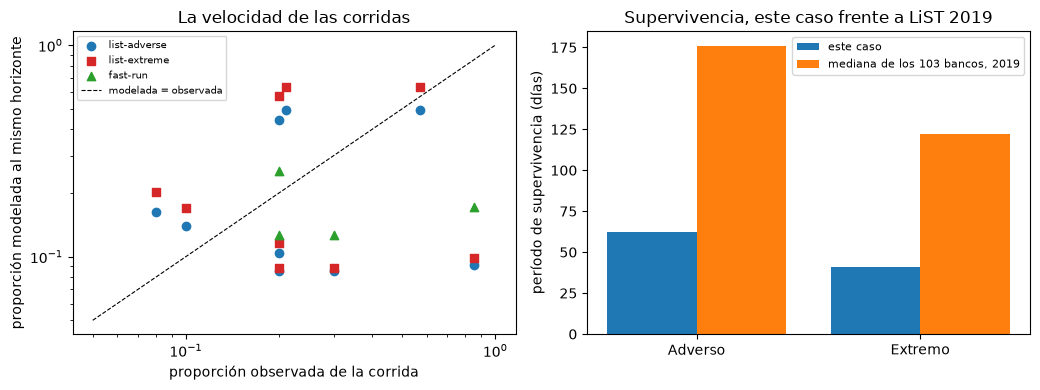

In [7]:
# Dibujar la proporción modelada contra la observada de cada corrida, y los períodos de supervivencia contra las medianas de la prueba de 2019
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))

for (name, shares), color, marker in zip(modelled.items(), ("tab:blue", "tab:red", "tab:green"), ("o", "s", "^")):
    points = [(run.outflow_share, shares[run.row_id]) for run in TABLE_A1 if shares[run.row_id] is not None]
    left.scatter([p[0] for p in points], [p[1] for p in points], color=color, marker=marker, label=name)
left.plot([0.05, 1.0], [0.05, 1.0], color="black", linestyle="--", linewidth=0.8, label="modelada = observada")
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("proporción observada de la corrida")
left.set_ylabel("proporción modelada al mismo horizonte")
left.set_title("La velocidad de las corridas")
left.legend(fontsize=7)

positions = np.arange(2)
right.bar(positions - 0.2, [variants[n]["outputs"]["path"]["survival"]["day"] for n in ("list-adverse", "list-extreme")], width=0.4, label="este caso")
right.bar(positions + 0.2, [LIST_2019_MEDIAN["adverse"], LIST_2019_MEDIAN["extreme"]], width=0.4, label="mediana de los 103 bancos, 2019")
right.set_xticks(positions)
right.set_xticklabels(["Adverso", "Extremo"])
right.set_ylabel("período de supervivencia (días)")
right.set_title("Supervivencia, este caso frente a LiST 2019")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Supervivencia.** La NLP de LiST Adverso se vuelve negativa el día 62 y la de Extremo el día 41, ambas con su mínimo el día 125 (-40,97 y -65,65 mil millones de USD); la corrida rápida sobrevive su horizonte de 5 días, con un mínimo de 13,80 mil millones el día 1. El motor reproduce la supervivencia versionada de las tres.
- **Velocidad al horizonte de cada corrida.** En las corridas de uno y dos días las tres variantes pierden mucho menos que las corridas: 0,0854, 0,0887 y 0,1263 frente a 0,30 (SVB UK) y 0,20 (Signature), y 0,0915, 0,0980 y 0,1708 frente a 0,85 (SVB). La corrida rápida, calibrada antes de 2023, se acerca más pero sigue en cerca de una quinta parte de la pérdida de SVB. A los 90 días el panorama cambia: Adverso (0,4955) queda bajo el 0,57 de First Republic y Extremo (0,6323) sobre él, y ambos sobre el 0,21 de Credit Suisse; las corridas lentas de 2008 (Icesave, IndyMac, WaMu) quedan todas cubiertas con holgura, mientras que Northern Rock (0,20 en 4 días frente a 0,1036 y 0,1164) no. Las tasas suaves son conservadoras para corridas lentas y demasiado lentas para las rápidas.
- **Cuánto más rápido.** La tasa diaria implícita de SVB, 0,612702, es 89,0 veces la tasa que LiST Adverso da a la clase corporativa no asegurada y 57,5 veces la de Extremo, y 36,3 veces la tasa diaria del tope del rango de depósitos del LCR (40% en 30 días, 0,016883). La salida neta del LCR del documento (0,4726) es 2,1158 veces su stock de HQLA.
- **Frente al estado del arte.** Los períodos de supervivencia de este caso, 62 y 41 días, son cerca de un tercio de las medianas de la prueba de 2019, 176 y 122 días (razones de 0,35 y 0,34). Los 103 bancos son balances reales con sus propios depósitos y activos, y este caso es un banco con comportamiento sintético, así que la razón dice que el mismo método da períodos de supervivencia del orden de meses, no que el banco quede bajo la muestra.

Lo que esta comparación no muestra: que la corrida rápida del producto sea un pronóstico (es una calibración rotulada con corridas anteriores a 2023), que el banco habría sobrevivido o fallado con estos números (su comportamiento es sintético), ni que LiST esté equivocado (responde la pregunta para la que fue diseñado: una fuga lenta e idiosincrática en seis meses).

## Resumen

- La fuga suave de LiST y la corrida rápida son dos respuestas a dos preguntas; sobre el mismo balance difieren en órdenes de magnitud en la velocidad que suponen.
- Evaluadas frente a las corridas de 2023, las variantes suaves pierden mucho menos que las corridas de uno y dos días (SVB UK, Signature, SVB) y son conservadoras para las corridas lentas de 2008; la corrida rápida, calibrada solo con corridas anteriores, mejora sobre ellas y aun así pierde cerca de una quinta parte de lo que perdió SVB.
- La salida a 30 días del LCR es más rápida que las tasas suaves de LiST pero mucho más lenta que las corridas de 2023.
- El producto sigue el método del BCE y agrega lo que el dosier lista como el resto de la escalera; no afirma un pronóstico.

**Qué probar a continuación.** Agrega la severidad Base de LiST a la comparación del paso 1 y mira si el período de supervivencia se alarga; luego sigue con el cuaderno 08, que convierte la distancia a las corridas de 2023 en un número.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155
- Cookson, J. A., Fox, C., Gil-Bazo, J., Imbet, J. F. and Schiller, C. (2026), Social media as a bank run catalyst, Journal of Financial Economics 176. https://doi.org/10.1016/j.jfineco.2025.104218
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899